In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [2]:
import os
from pathlib import Path

from dataset.dataset import anonymize_dataset, create_dataset
from dataset.utils import link_dir
from plotting import plot_metrics
from training import *


# Parameters

In [3]:
n = 3

# Goal
Benchmark the model "yolo11-cls" model on an increasing quantity of data.

The dataset has been already tested and the model too (KFold cross validation).

Just change the training dataset quantity but keep the same test dataset
- 20% -> 40% -> 60% -> 80% -> 100

### Create datasets

In [4]:
quantities = [0.2, 0.4, 0.6, 0.8, 1.0]
path = "dataset/benchmark"
path_csv = "dataset/benchmark"

anonymize_dataset("dataset/source/csv/sources_kfold_train.csv")

for q in quantities:
    for i in range(n):
        create_dataset("dataset/source/csv/sources_kfold_train.csv", 
                       f"dataset/benchmark/kfold_{q}/{i}/train", 
                       f"dataset/source/csv/benchmark/kfold_{q}/{i}.csv", quantity=q, random=True)
        link_dir("dataset/main/test",
                 f"dataset/benchmark/kfold_{q}/{i}/test")


### Training

In [6]:
def benchmark_dataset_yolo(config, datasets: list[str], names, n=3):
    # mean of (score, accuracy, recall, f1)
    histories = []
    for ds_path in datasets:
        
        results = []
        for i in range(n):
            name = os.path.basename(ds_path)
            
            ds = Path(ds_path, str(i))
            
            model = train(name, ds, config)
            _, metric = test(model, ds)
            
            results.append(metric[0])

        results = np.asarray(results)
        histories.append([(results.mean(), results.std())])
        
    print(histories)
    plot_metrics(histories, names, metrics=[("accuracy", "number of images")])

New https://pypi.org/project/ultralytics/8.4.176 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.150  Python-3.12.10 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5090, 32607MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset\benchmark\kfold_0.2\0, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train,

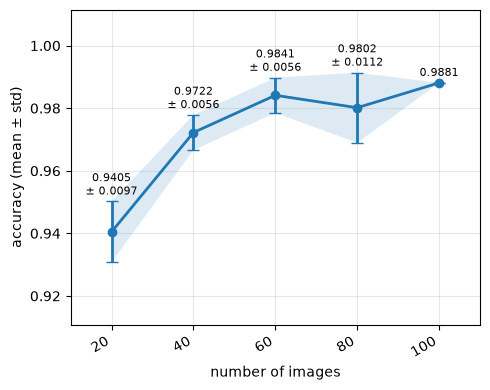

In [7]:
config = {"model": "models/yolo11x-cls.pt", 
            "optimizer": 'SGD',
            "batch": 16,
            "epochs": 100,
            "imgsz": 512,
        }
# "dataset/benchmark/kfold_0.4/", "dataset/benchmark/kfold_0.6/", "dataset/benchmark/kfold_0.8/", "dataset/main/"
# "40", "60", "80", "100"

# benchmark_dataset_yolo(config, ["dataset/benchmark/kfold_0.2/"], ["20"])
benchmark_dataset_yolo(config, ["dataset/benchmark/kfold_0.2/", 
                                "dataset/benchmark/kfold_0.4/", 
                                "dataset/benchmark/kfold_0.6/", 
                                "dataset/benchmark/kfold_0.8/", 
                                "dataset/benchmark/kfold_1.0/"], 
                       ["20", "40", "60", "80", "100"])